# Powerex Corner & Squeeze — Abstract Model and 9-Bus Illustration

Two views of the same strategy, side by side, so the mechanism is concrete:

1. **Part I — abstract three-node model** (`western_seams.markets.canonical_corner`,
   writeup `notes/powerex/powerex_writeup.tex`): a single convex program for how a
   strategic agent $Z$ sources a long-term delivery obligation with hydro at $\lambda$,
   transmission rights, and spot purchases.
2. **Part II — IEEE 9-bus illustration** (`powerex_corner.py`): the *same* story staged
   on the canonical 9-bus testbed, cleared with the existing Egret **SCED** engine
   (`clearing.sced_clearing.clear_sced`) — **no RL agents**, just a deterministic
   dispatch you re-run after moving variables.

**Kernel:** run this notebook with the **`assume`** conda env (it has egret, pandapower,
pypsa, pycirclize). The three-node module is imported from the western-seams repo via
`sys.path`; the 9-bus pieces are local testbed imports.

The 9-bus maps onto the three-node model like this:

| three-node model | 9-bus illustration |
|---|---|
| node A — hydro at water value $\lambda$ | **bus 1** (with the \$20 slack unit) |
| A–B–C, **no** A–C link | congested mesh: **line_1 (4→5)** capped at 90 MW |
| node C — scarce LT load | **bus 5** (isolated downstream, ~\$60 LMP) |
| $K_{BC}$ binding | the 4→5 corridor isolating bus 5 |
| transmission-rights option value | a **financial transmission right** 1→5 |


In [13]:
# --- Setup (run with the `assume` kernel) --------------------------------
import sys, importlib, contextlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib

# Local testbed imports (nodal_plot + the Powerex 9-bus helpers).
TESTBED = str(Path.cwd())
if TESTBED not in sys.path:
    sys.path.insert(0, TESTBED)
from nodal_plot import (
    plot_nodal_circlize, plot_network_topology, assign_bus_colors,
    BUS_PALETTE, TRANSIT_COLOR,
)
import powerex_corner as px
importlib.reload(px)

# The abstract three-node model lives in the western-seams repo. Point this at
# your checkout; only the light canonical_corner module is imported (numpy/
# pandas/scipy/pypsa) — no heavy western-seams deps are pulled in.
WESTERN_SEAMS_ROOT = r"C:\Users\docke\Projects\western-seams"
if WESTERN_SEAMS_ROOT not in sys.path:
    sys.path.insert(0, WESTERN_SEAMS_ROOT)
import western_seams.markets.canonical_corner as cc
importlib.reload(cc)
from western_seams.markets.canonical_corner import (
    CanonicalParams, solve_canonical, result_to_viz_data,
    build_3node_network, build_scenarios, rent_decomposition, sweep,
)

# Chord ribbon geometry (SCOPED). pycirclize's default link height_ratio=0.5
# renders proper ribbons when there are many narrow flows (the 9-bus, like
# presentation_charts.ipynb). But with only 3 wide sectors each flow is ~a
# whole sector, so the fat ribbon collapses into a pie wedge — there we want a
# lower height. So the override is OFF by default and applied only inside the
# `chord_height(...)` context manager (used for the 3-node chord). Idempotent;
# leaves the shared nodal_plot module untouched.
import pycirclize
_orig_link = getattr(pycirclize.Circos, "_orig_link", pycirclize.Circos.link)
pycirclize.Circos._orig_link = _orig_link
_CHORD_HR = {"val": None}   # None => use pycirclize default (0.5)
def _chord_link(self, *a, **k):
    if _CHORD_HR["val"] is not None:
        k.setdefault("height_ratio", _CHORD_HR["val"])
    return _orig_link(self, *a, **k)
pycirclize.Circos.link = _chord_link

@contextlib.contextmanager
def chord_height(ratio):
    """Temporarily set the chord ribbon height_ratio for plots inside the block."""
    prev = _CHORD_HR["val"]
    _CHORD_HR["val"] = ratio
    try:
        yield
    finally:
        _CHORD_HR["val"] = prev

matplotlib.rcParams.update({
    "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.bbox": "tight",
})
print("setup OK")


setup OK


# Part I — Abstract three-node model

The deliberately abstract version: nodes A–B–C (lines A–B and B–C only), agent $Z$
holding hydro at A (water value $\lambda$), firm rights $K_{AB}, K_{BC}$, and an
obligation to deliver $\bar Q$ to load at C. $Z$ minimises sourcing cost over
$h_C, h_B, s_B, s_C$. Edit `PARAMS3` and re-run.

In [14]:
PARAMS3 = dict(
    Qbar=1000.0, P_LT=50.0, lam=25.0,
    a_B=30.0, b_B=0.10, a_C=60.0, b_C=0.20,
    hbar=500.0, K_AB=800.0, K_BC=1000.0,
)
p3 = CanonicalParams(**PARAMS3)
r3 = solve_canonical(p3)
viz3 = result_to_viz_data(r3)
print(f"h_C={r3.h_C:.0f}  h_B={r3.h_B:.0f}  s_B={r3.s_B:.0f}  s_C={r3.s_C:.0f}"
      f"   cost=${r3.cost:,.0f}   profit=${r3.profit:,.0f}")
print(f"node prices  A(lambda)=${r3.lmp_A:.1f}  B=${r3.lmp_B:.1f}  C=${r3.lmp_C:.1f}"
      f"   binding: {', '.join(r3.binding) or 'none'}")

h_C=500  h_B=0  s_B=383  s_C=117   cost=$48,417   profit=$1,583
node prices  A(lambda)=$25.0  B=$68.3  C=$83.3   binding: A->B / hydro (cap_A)


### Topology and chord (3-node)

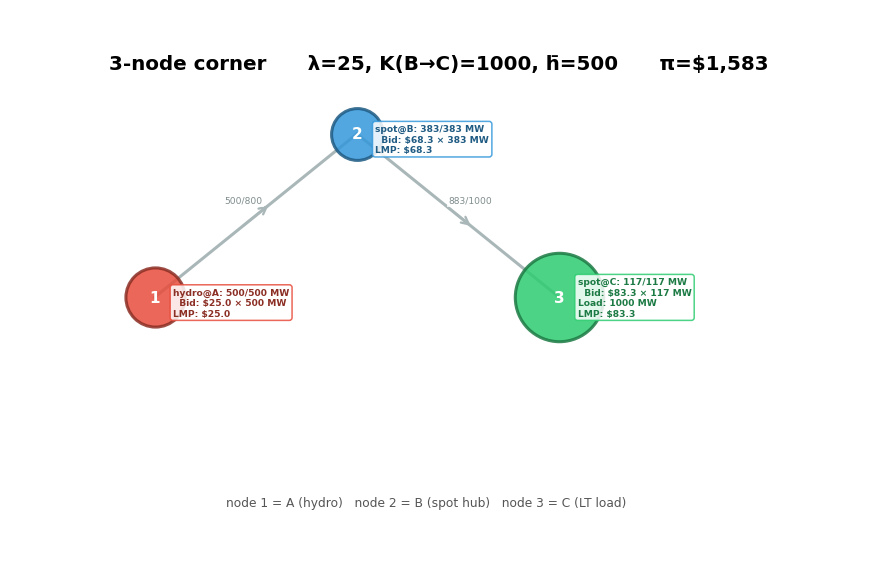

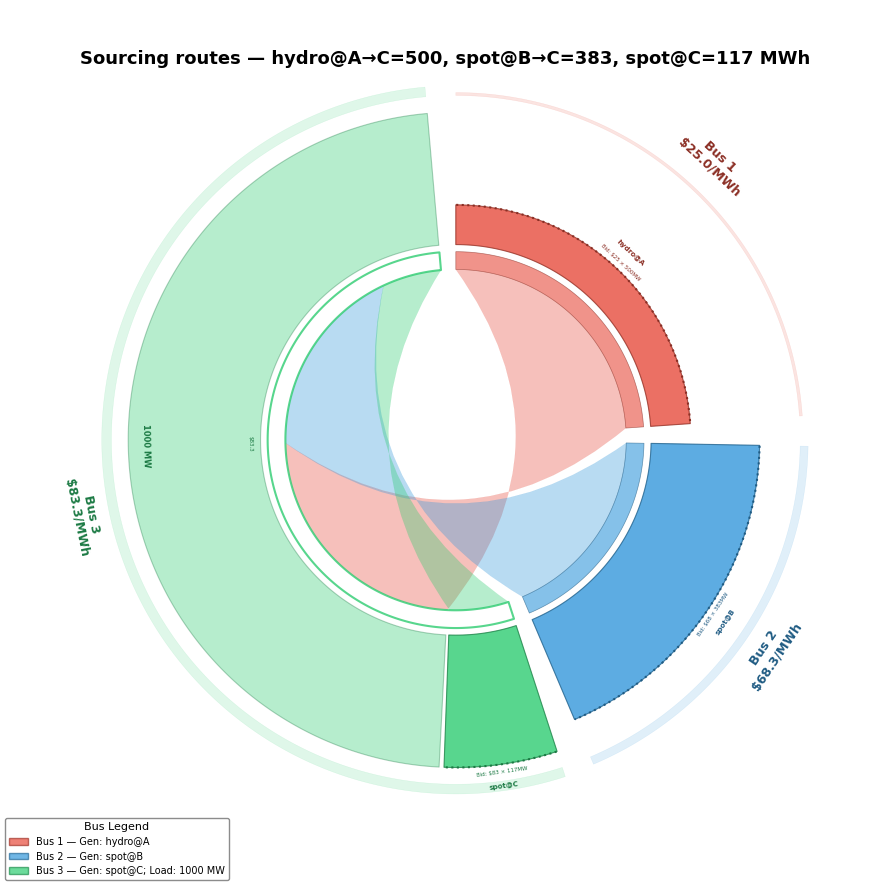

In [15]:
colors3 = assign_bus_colors(viz3["all_buses"], viz3["supply_by_bus"], viz3["demand_by_bus"])
net3 = build_3node_network(p3)
fig, ax = plot_network_topology(
    net3, supply_by_bus=viz3["supply_by_bus"], demand_by_bus=viz3["demand_by_bus"],
    bus_colors=colors3, bus_coords=viz3["bus_coords"], bus_lmps=viz3["bus_lmps"],
    line_flows=viz3["line_flows"],
    title=(f"3-node corner      λ={p3.lam:.0f}, K(B→C)={p3.K_BC:.0f}, "
           f"h̄={p3.hbar:.0f}      π=${r3.profit:,.0f}".replace("$", r"\$")))
fig.text(0.5, 0.01, "node 1 = A (hydro)   node 2 = B (spot hub)   node 3 = C (LT load)",
         ha="center", va="bottom", fontsize=8, color="#555")
# Node 3 (C) is large (sized by its 1000 MW load) and sits at the right edge,
# so its marker + annotation box get clipped. Pad the view: extra room on the
# right for the C box, a little on the left for A, and headroom for the B box.
x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
ax.set_xlim(x0 - 0.5, x1 + 2.6)
ax.set_ylim(y0 - 0.5, y1 + 0.4)
fig.set_size_inches(9.0, 5.6); fig.subplots_adjust(bottom=0.08); plt.show()

# 3 wide sectors -> use a low ribbon height so chords don't collapse to wedges.
with chord_height(0.15):
    fig = plot_nodal_circlize(
        viz3["supply_by_bus"], viz3["demand_by_bus"], viz3["all_buses"],
        flows=viz3["flows"], bus_lmps=viz3["bus_lmps"], bus_colors=colors3,
        gen_marginal_costs=viz3["gen_marginal_costs"],
        title=(f"Sourcing routes — hydro@A→C={r3.h_C:.0f}, spot@B→C={r3.s_B:.0f}, "
               f"spot@C={r3.s_C:.0f} MWh"))
fig.set_size_inches(8, 8); plt.show()


### Rent decomposition (3-node)

In [16]:
scen = build_scenarios(p3)
disp = scen.copy()
for c in ["hbar","h_C","h_B","s_B","s_C","cost","profit"]:
    disp[c] = disp[c].round(0).astype(int)
display(disp)
rent = rent_decomposition(p3)
print(f"\nTotal corner rent   = ${rent['total_rent']:,.0f}"
      f"   (transmission ${rent['transmission_layer']:,.0f} "
      f"+ reservoir ${rent['reservoir_layer']:,.0f})")

,hbar,PTP,h_C,h_B,s_B,s_C,cost,profit
scenario,,,,,,,,
(a) No portfolio,0,no,0,0,0,1000,260000,-210000
(b) PTP only,0,yes,0,0,717,283,105917,-55917
(c) PTP + moderate hydro,500,yes,500,0,383,117,48417,1583
(d) PTP + ample hydro,700,yes,700,0,250,50,34750,15250



Total corner rent   = $225,250   (transmission $154,083 + reservoir $71,167)


# Part II — IEEE 9-bus illustration

Same strategy on the canonical 9-bus, cleared with the testbed's Egret SCED. The
congested preset (`line_1`, `line_5` → 90 MW) isolates **bus 5** at a high LMP while
the cheap hydro sits at **bus 1**. Powerex is **not** an RL agent — its reservoir is
just an extra supply bid at water value `lam`, and its long-term obligation an extra
load at bus 5. Move `PARAMS9` and re-run.

In [17]:
PARAMS9 = dict(
    lam          = 15.0,   # Powerex reservoir water value / bid ($/MWh)
    release_cap  = 150.0,  # reservoir power at bus 1 (MW)
    Q_LT         = 150.0,  # long-term obligation delivered at bus 5 (MWh/h)
    P_LT         = 70.0,   # long-term contract price ($/MWh)
    ftr_mw       = 100.0,  # financial transmission right, bus 1 -> bus 5 (MW)
    peak_hour    = 12,     # hour for the single-period spatial-corner scene
    energy_budget= 600.0,  # reservoir daily energy budget (MWh) for Part II.B
    line1_limit  = 90.0,   # 4->5 corridor rating (the binding constraint)
    line5_limit  = 90.0,   # 7->8 corridor rating
)
LINE_OVR = {"line_1": PARAMS9["line1_limit"], "line_5": PARAMS9["line5_limit"]}
print("PARAMS9 set.")

PARAMS9 set.


## II.A — Spatial corner: arbitraging nodes you are not connected to

One peak hour. Powerex injects cheap hydro at **bus 1**, but its rents come from
**bus 5**, where it owns no generator:

- **LT margin** — it owes $\bar Q$ at bus 5 for fixed $P^{LT}$; the spot cost of
  sourcing there is $\text{LMP}_5$, so it earns $(P^{LT}-\text{LMP}_5)\,\bar Q$.
- **FTR rent** — a financial transmission right 1→5 pays
  $(\text{LMP}_5-\text{LMP}_1)\times\text{FTR}$ — pure congestion arbitrage between
  nodes it has no physical asset at. This is the Joskow–Tirole transmission-rights
  option value.

In [18]:
H = PARAMS9["peak_hour"]
net9 = px.build_network(periods=24, line_overrides=LINE_OVR)
extra = {H: [
    dict(price=PARAMS9["lam"], volume=PARAMS9["release_cap"],
         node=px.STORAGE_BUS, unit_id="powerex_hydro"),
    dict(price=px.VOLL, volume=-PARAMS9["Q_LT"],
         node=px.LT_BUS, unit_id="powerex_LT"),
]}
d9 = px.clear(net9, [H], extra_orders=extra,
              capacities={"powerex_hydro": PARAMS9["release_cap"]})

release = d9.dispatch(H).get("powerex_hydro", 0.0)
pnl = px.corner_pnl(d9, H, lam=PARAMS9["lam"], release_mw=release,
                    Q_LT=PARAMS9["Q_LT"], P_LT=PARAMS9["P_LT"], ftr_mw=PARAMS9["ftr_mw"])
print(f"hour {H}:  LMP bus1=${pnl['lmp_storage']:.1f}   LMP bus5=${pnl['lmp_lt']:.1f}"
      f"   congestion spread=${pnl['congestion_spread']:.1f}")
print(f"reservoir dispatched at bus 1: {release:.0f} MW (of {PARAMS9['release_cap']:.0f})")
print("-"*58)
print(f"  storage margin (bus1, LMP-λ)         = ${pnl['storage_margin']:,.0f}")
print(f"  LT margin      (P_LT - LMP5)·Q       = ${pnl['lt_margin']:,.0f}")
print(f"  FTR rent       (LMP5 - LMP1)·FTR     = ${pnl['ftr_rent']:,.0f}")
print(f"  --------------------------------------------------")
print(f"  Powerex total period profit          = ${pnl['total']:,.0f}")

Unsupported features include: three-winding transformers, switches, in_service status, shunt impedances and tap positions of transformers.
INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines
INFO:clearing.sced_clearing:Solving Egret SCED (relaxed=True)...
Calculating PTDF Matrix Factorization
INFO:egret:Calculating PTDF Matrix Factorization
Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP has 60 rows; 43 cols; 79 nonzeros
Coefficient ranges:
  Matrix  [8e-01, 5e+03]
  Cost    [1e+00, 1e+08]
  Bound   [1e+00, 4e+00]
  RHS     [1e+00, 5e+00]
Presolving model
1 rows, 10 cols, 10 nonzeros  0s
1 rows, 6 cols, 6 nonzeros  0s
Dependent equations search running on 1 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1 rows, 6 cols, 6 nonzeros  0s
Presolve reductions: rows 1(-59); columns 6(-37); nonzeros 6(-73) 
Solving the presolved LP
Using dual simplex solver


### LMP map at the peak hour (topology + chord)

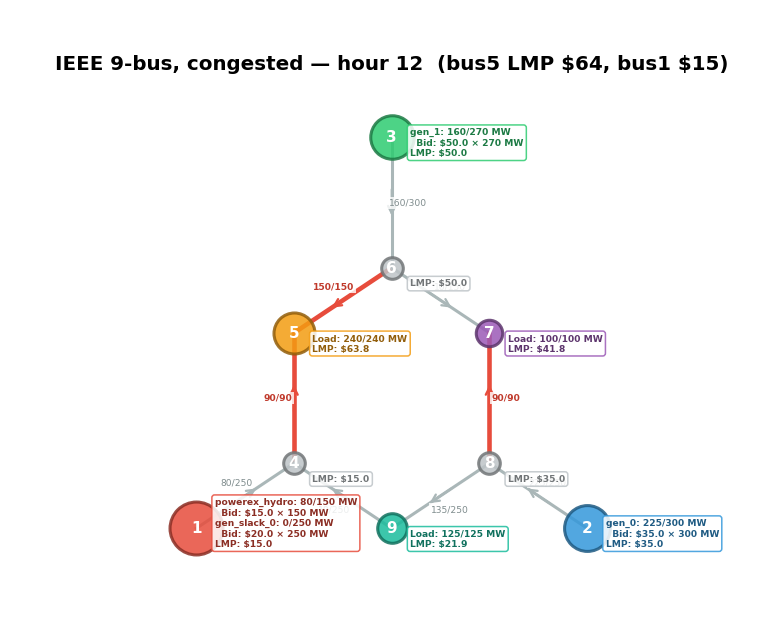

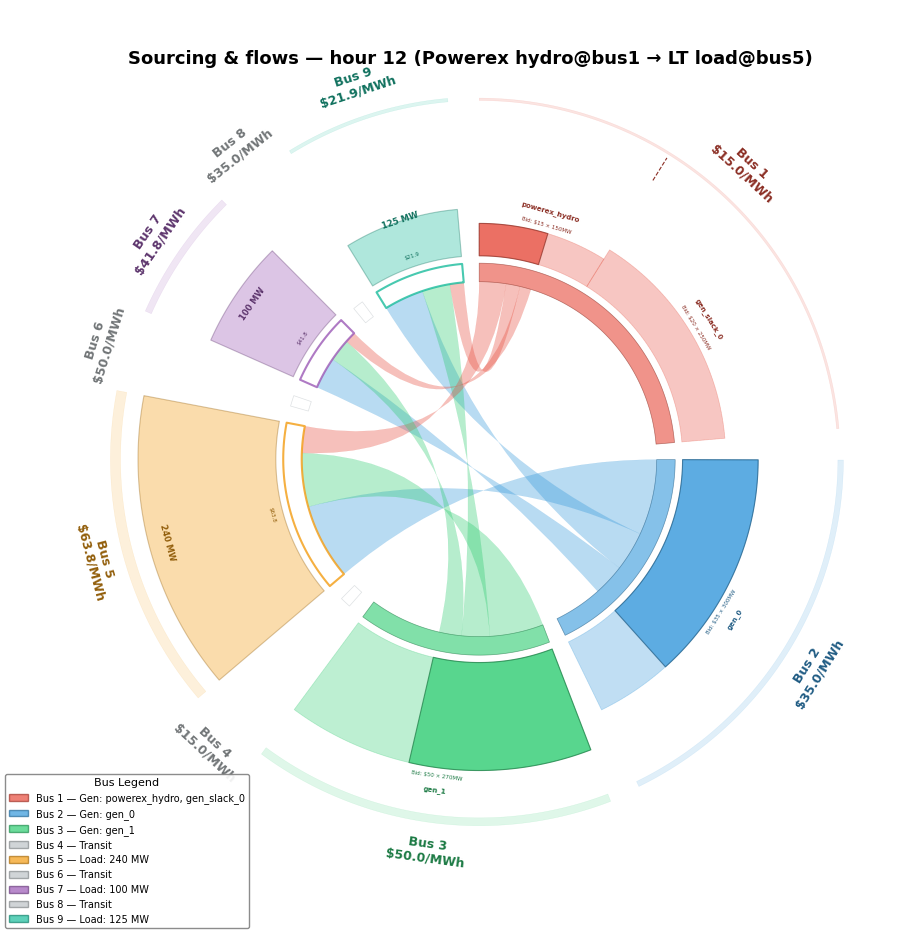

In [19]:
sb, db, ds, lmps, lf = px.get_hour_data(d9, H)
colors9 = assign_bus_colors(sorted(net9.buses.index, key=int), sb, db)
fig, ax = plot_network_topology(
    net9, supply_by_bus=sb, demand_by_bus=db, bus_colors=colors9,
    bus_lmps=lmps, demand_served_by_bus=ds, line_flows=lf,
    title=(f"IEEE 9-bus, congested — hour {H}  "
           f"(bus5 LMP ${lmps.get('5',0):.0f}, bus1 ${lmps.get('1',0):.0f})".replace("$", r"\$")))
fig.set_size_inches(7.5, 6.0); plt.show()

fig = plot_nodal_circlize(
    sb, db, sorted(net9.buses.index, key=int), bus_lmps=lmps, bus_colors=colors9,
    title=f"Sourcing & flows — hour {H} (Powerex hydro@bus1 → LT load@bus5)")
fig.set_size_inches(8.5, 8.5); plt.show()

## II.B — Intertemporal squeeze: arbitraging long-duration storage

Now 24 hours. Bus 5's LMP swings with the diurnal load (cheap off-peak, scarce at
peak). Powerex's reservoir has a daily energy budget; the lever is **when** to release
it. A price-taking, intertemporally-constrained competitor releases flat; Powerex,
with a multi-hour reservoir, concentrates release into the highest-price hours.

> Releases are valued at the bus-5 LMP profile from the no-Powerex baseline (a
> price-taker view). The bottom cell re-clears with the release injected so you can
> see the price *impact* — concentrating into the peak partly flattens it, which is
> the squeeze acting on buyers (and the self-limiting force on the arbitrage).

Unsupported features include: three-winding transformers, switches, in_service status, shunt impedances and tap positions of transformers.
INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines
INFO:clearing.sced_clearing:Solving Egret SCED (relaxed=True)...
Calculating PTDF Matrix Factorization
INFO:egret:Calculating PTDF Matrix Factorization
Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP has 903 rows; 864 cols; 1722 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 5e+03]
  Cost    [1e+00, 1e+08]
  Bound   [5e-01, 3e+00]
  RHS     [5e-01, 3e+00]
Presolving model
24 rows, 216 cols, 216 nonzeros  0s
24 rows, 120 cols, 120 nonzeros  0s
Dependent equations search running on 24 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
24 rows, 120 cols, 120 nonzeros  0s
Presolve reductions: rows 24(-879); columns 120(-744); nonzeros 120(-1602) 
Solving the presolved LP

,hours_used,avg_capture_$,profit_$
strategy,,,
flat,24,43.4,17021
peak,4,60.4,27220


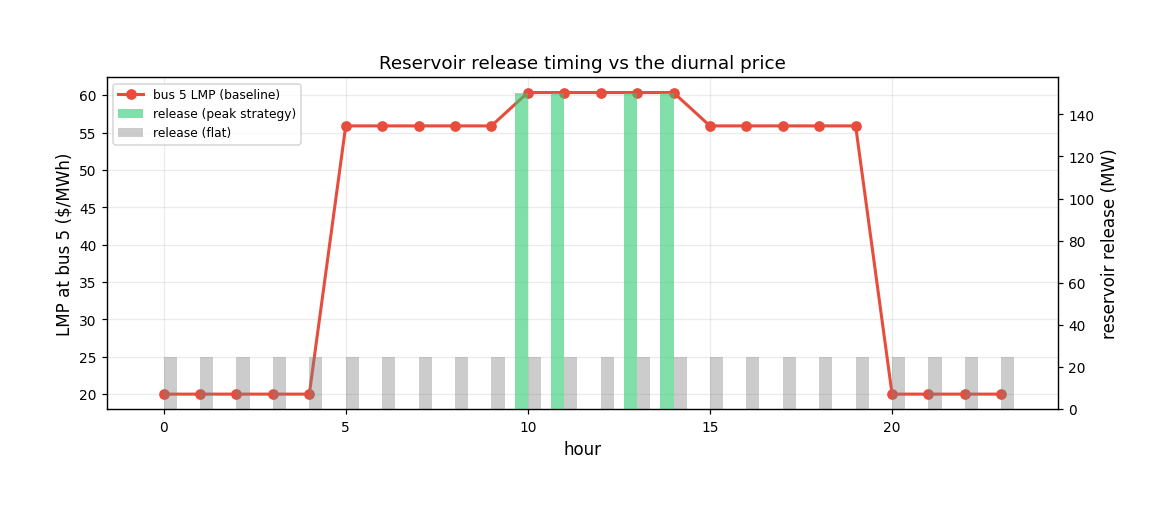

In [20]:
net_t = px.build_network(periods=24, line_overrides=LINE_OVR)
base = px.clear(net_t, range(24))
lmp5 = base.lmp_series(px.LT_BUS)

E, P, LAM = PARAMS9["energy_budget"], PARAMS9["release_cap"], PARAMS9["lam"]
rows = []
for strat in ["flat", "peak"]:
    rel = px.release_schedule(lmp5, E, P, strategy=strat)
    pnl_t = px.intertemporal_pnl(base, rel, lam=LAM, bus=px.LT_BUS)
    rows.append({"strategy": strat, "hours_used": int((rel > 0.1).sum()),
                 "avg_capture_$": round(pnl_t["avg_capture_price"], 1),
                 "profit_$": round(pnl_t["profit"])})
display(pd.DataFrame(rows).set_index("strategy"))

rel_peak = px.release_schedule(lmp5, E, P, strategy="peak")
rel_flat = px.release_schedule(lmp5, E, P, strategy="flat")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lmp5.index, lmp5.values, "-o", color=BUS_PALETTE[0], lw=2, label="bus 5 LMP (baseline)")
ax.set_xlabel("hour"); ax.set_ylabel("LMP at bus 5 ($/MWh)")
ax2 = ax.twinx()
ax2.bar(rel_peak.index - 0.18, rel_peak.values, width=0.36, color=BUS_PALETTE[2],
        alpha=0.6, label="release (peak strategy)")
ax2.bar(rel_flat.index + 0.18, rel_flat.values, width=0.36, color="gray",
        alpha=0.4, label="release (flat)")
ax2.set_ylabel("reservoir release (MW)")
ax.set_title("Reservoir release timing vs the diurnal price")
l1, la1 = ax.get_legend_handles_labels(); l2, la2 = ax2.get_legend_handles_labels()
ax.legend(l1 + l2, la1 + la2, loc="upper left", fontsize=8)
ax.grid(True, alpha=0.25); fig.tight_layout(); plt.show()

### Energy-budget sweep — diminishing returns as the spread is arbitraged away

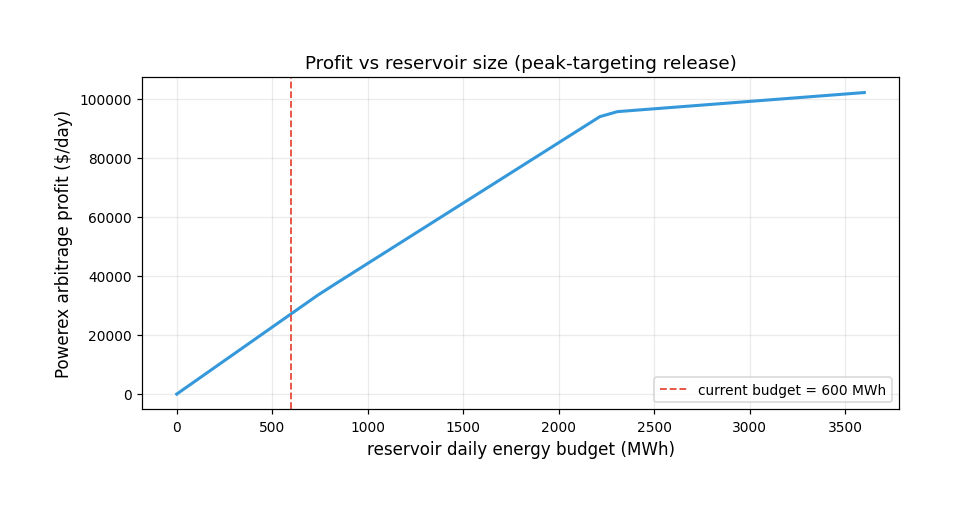

Concavity = the squeeze competing itself away: each extra MWh is forced
into a lower-price hour, so marginal capture price falls toward off-peak.


In [21]:
budgets = np.linspace(0, 24 * P, 40)
prof = []
for E_ in budgets:
    rel = px.release_schedule(lmp5, E_, P, strategy="peak")
    prof.append(px.intertemporal_pnl(base, rel, lam=LAM, bus=px.LT_BUS)["profit"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(budgets, prof, color=BUS_PALETTE[1], lw=2)
ax.axvline(E, color=BUS_PALETTE[0], ls="--", lw=1.2, label=f"current budget = {E:.0f} MWh")
ax.set_xlabel("reservoir daily energy budget (MWh)")
ax.set_ylabel("Powerex arbitrage profit ($/day)")
ax.set_title("Profit vs reservoir size (peak-targeting release)")
ax.legend(); ax.grid(True, alpha=0.25); fig.tight_layout(); plt.show()
print("Concavity = the squeeze competing itself away: each extra MWh is forced")
print("into a lower-price hour, so marginal capture price falls toward off-peak.")

### Re-clear with the release injected — the price impact (the squeeze itself)

Inject Powerex's peak-strategy release as supply at bus 5 and re-clear. The peak LMP
falls where Powerex discharges — the mechanical signature of the squeeze on buyers,
and why a price-taker valuation overstates the rent.

INFO:clearing.sced_clearing:Solving Egret SCED (relaxed=True)...
Calculating PTDF Matrix Factorization
INFO:egret:Calculating PTDF Matrix Factorization
Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP has 1120 rows; 1036 cols; 2037 nonzeros
Coefficient ranges:
  Matrix  [8e-01, 5e+03]
  Cost    [1e+00, 1e+08]
  Bound   [5e-01, 3e+00]
  RHS     [5e-01, 3e+00]
Presolving model
24 rows, 224 cols, 224 nonzeros  0s
24 rows, 124 cols, 124 nonzeros  0s
Dependent equations search running on 24 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
24 rows, 124 cols, 124 nonzeros  0s
Presolve reductions: rows 24(-1096); columns 124(-912); nonzeros 124(-1913) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Pr: 24(56.0864) 0.0s
         24     1.1257360840e+05 Pr: 0(0) 0.0s

Performed postsolve
Sol

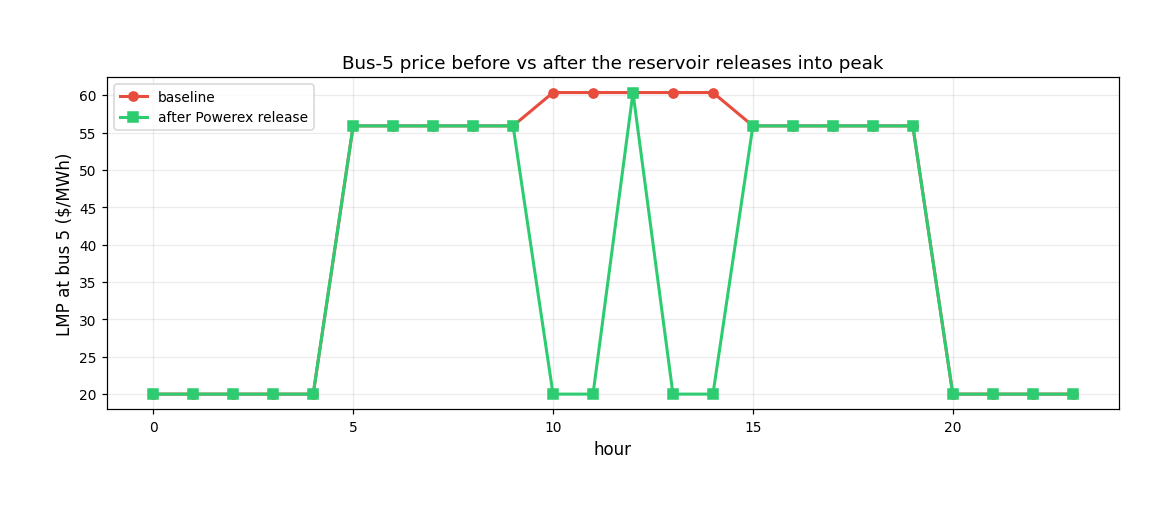

price-taker (baseline prices) profit = $27,220
realized (re-cleared) profit          = $3,000
price impact erodes                   = $24,220


In [22]:
rel_peak = px.release_schedule(lmp5, E, P, strategy="peak")
extra_t = {int(h): [dict(price=LAM, volume=float(v), node=px.LT_BUS,
                         unit_id="powerex_release")]
           for h, v in rel_peak.items() if v > 0.1}
withpx = px.clear(net_t, range(24), extra_orders=extra_t,
                  capacities={"powerex_release": P})
lmp5_after = withpx.lmp_series(px.LT_BUS)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lmp5.index, lmp5.values, "-o", color=BUS_PALETTE[0], lw=2, label="baseline")
ax.plot(lmp5_after.index, lmp5_after.values, "-s", color=BUS_PALETTE[2], lw=2,
        label="after Powerex release")
ax.set_xlabel("hour"); ax.set_ylabel("LMP at bus 5 ($/MWh)")
ax.set_title("Bus-5 price before vs after the reservoir releases into peak")
ax.legend(); ax.grid(True, alpha=0.25); fig.tight_layout(); plt.show()

realized = float((rel_peak * lmp5_after).sum() - LAM * rel_peak.sum())
naive = px.intertemporal_pnl(base, rel_peak, lam=LAM, bus=px.LT_BUS)["profit"]
print(f"price-taker (baseline prices) profit = ${naive:,.0f}")
print(f"realized (re-cleared) profit          = ${realized:,.0f}")
print(f"price impact erodes                   = ${naive - realized:,.0f}")

## Reading the two parts together

- **Part I** isolates the economics: each rent layer (transmission, reservoir) is
  visible in a closed-form cost decomposition.
- **Part II.A** shows the same transmission-rights rent emerging *endogenously* from
  nodal congestion — Powerex profits at bus 5 via an FTR while only generating at
  bus 1. "Arbitraging nodes you're not connected to."
- **Part II.B** shows the reservoir's intertemporal edge: concentrating a fixed energy
  budget into scarcity hours, an option intertemporally-constrained competitors lack.
  The re-clear makes the price impact (the squeeze on buyers) explicit.

Levers to try: tighten `line1_limit` (deeper congestion → wider spread → more FTR
rent); raise `lam` toward bus-5 spot (reservoir edge collapses, as in the writeup's
single-period benchmark); grow `energy_budget` (profit saturates as the spread is
arbitraged away).